# SNOTEL download: Headwaters of the Snake River

Downloads full period-of-record **daily** data for 8 SNOTEL sites (by Site ID) from the NRCS AWDB REST API and saves one combined CSV.

Run the cells top to bottom. In VS Code, pick a Python kernel (top right) first.

## 1. Install / import

In [1]:
# Uncomment if requests/pandas/matplotlib aren't installed in your kernel
# %pip install requests pandas matplotlib

import time
import requests
import pandas as pd

## 2. Sites and variables

In [2]:
BASE = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1"
OUT_CSV = "snotel_snake.csv"

# (site_id, state, name, basin)
SITES = [
    # Headwaters of the Snake River (Wyoming)
    (314, "WY", "Base Camp",            "Snake River Headwaters"),
    (499, "WY", "Grassy Lake",          "Snake River Headwaters"),
    (577, "WY", "Lewis Lake Divide",    "Snake River Headwaters"),
    (764, "WY", "Snake River Station",  "Snake River Headwaters"),
    (822, "WY", "Togwotee Pass",        "Snake River Headwaters"),
    (837, "WY", "Two Ocean Plateau",    "Snake River Headwaters"),
    (878, "WY", "Younts Peak",          "Snake River Headwaters"),
    (816, "WY", "Thumb Divide",         "Snake River Headwaters"),
]

# WTEQ=SWE (in), PREC=accum. precip (in), PRCP=incremental precip (in),
# TOBS/TMAX/TMIN/TAVG=air temp (F), RHUM/RHUMV=relative humidity (%),
# SMS=soil moisture (% by depth), PRES=pressure (rare on SNOTEL)
WANTED = ["WTEQ", "PREC", "PRCP", "TOBS", "TMAX", "TMIN", "TAVG",
          "RHUM", "RHUMV", "SMS", "PRES"]

## 3. Helper functions

In [3]:
def get(path, params, tries=4):
    for i in range(tries):
        try:
            r = requests.get(f"{BASE}/{path}", params=params, timeout=120)
            r.raise_for_status()
            return r.json()
        except Exception:
            if i == tries - 1:
                raise
            time.sleep(2 * (i + 1))


def col_name(code, depth):
    if depth is None:
        return code
    d = int(depth) if float(depth).is_integer() else depth
    return f"{code}_{d}in"   # e.g. SMS_-2in = 2 in below surface


def fetch_site(site_id, state, name, basin):
    triplet = f"{site_id}:{state}:SNTL"

    # Station metadata: which daily elements exist + start of record
    meta = get("stations", {"stationTriplets": triplet, "returnStationElements": "true"})
    if not meta:
        print(f"  !! no metadata for {triplet}")
        return None
    st = meta[0]
    begin = str(st.get("beginDate", "1980-01-01"))[:10]
    end = pd.Timestamp.today().strftime("%Y-%m-%d")

    combos = set()
    for el in st.get("stationElements", []):
        code = el.get("elementCode")
        if code in WANTED and el.get("durationName") == "DAILY":
            hd = el.get("heightDepth")
            depth = hd.get("value") if isinstance(hd, dict) else None
            combos.add((code, depth, el.get("ordinal", 1)))
    if not combos:
        print(f"  !! no wanted daily elements for {triplet}")
        return None

    cols = {}   # column name -> Series (names guaranteed unique)
    for code, depth, ordinal in sorted(combos, key=lambda x: (x[0], x[1] or 0, x[2])):
        el_str = code if depth is None else f"{code}:{int(depth)}:{ordinal}"
        try:
            data = get("data", {
                "stationTriplets": triplet, "elements": el_str, "duration": "DAILY",
                "beginDate": begin, "endDate": end, "periodRef": "END", "returnFlags": "false",
            })
        except Exception as e:
            print(f"  !! {triplet} {el_str} failed: {e}")
            continue
        for block in data:
            for series in block.get("data", []):
                vals = series.get("values", [])
                if not vals:
                    continue
                se = series.get("stationElement") or {}
                hd = se.get("heightDepth")
                d = hd.get("value") if isinstance(hd, dict) else depth
                name_ = col_name(code, d)
                if name_ in cols:                       # same variable/depth already seen
                    name_ = f"{name_}_ord{se.get('ordinal', ordinal)}"
                base, k = name_, 2
                while name_ in cols:                    # last-resort uniqueness
                    name_ = f"{base}_{k}"; k += 1
                cols[name_] = pd.Series({v["date"]: v.get("value") for v in vals})
    if not cols:
        return None

    df = pd.DataFrame(cols)
    df = df.loc[:, ~df.columns.duplicated()]
    df.index = pd.to_datetime(df.index)
    df.index.name = "date"
    df = df.reset_index()
    df.insert(1, "site_id", site_id)
    df.insert(2, "site_name", name)
    df.insert(3, "basin", basin)
    df.insert(4, "state", state)
    return df

## 4. Download (takes a few minutes)

In [4]:
out = []
for sid, state, name, basin in SITES:
    print(f"Fetching {sid} {name} ({state}) ...")
    df_site = fetch_site(sid, state, name, basin)
    if df_site is not None:
        print(f"  {len(df_site):,} rows, {df_site['date'].min().date()} -> {df_site['date'].max().date()}")
        out.append(df_site)

# --- Water year: Oct 1 -> Sep 30, named for the year it ENDS (Oct 1 2019 = WY2020) ---
df = pd.concat(out, ignore_index=True, sort=False)
df["water_year"] = df["date"].dt.year + (df["date"].dt.month >= 10).astype(int)
wy_start = pd.to_datetime((df["water_year"] - 1).astype(str) + "-10-01")
df["day_of_water_year"] = (df["date"] - wy_start).dt.days + 1   # Oct 1 = 1

# --- Annual (water-year) values, repeated on every row of that site/water year ---
# SWE:    peak SWE + date, total SWE accumulated, April 1 SWE
# precip: total water-year precipitation = max of accumulated PREC (it resets Oct 1)
df = df.sort_values(["site_id", "water_year", "date"]).reset_index(drop=True)
key = [df["site_id"], df["water_year"]]
g = df.groupby(["site_id", "water_year"])

if "WTEQ" in df:
    df["annual_swe_peak_in"] = g["WTEQ"].transform("max")
    peak_date = (df.loc[df["WTEQ"].notna()]
                   .sort_values("WTEQ", ascending=False)
                   .drop_duplicates(["site_id", "water_year"])
                   .set_index(["site_id", "water_year"])["date"])
    df["annual_swe_peak_date"] = [peak_date.get((a, b)) for a, b in zip(df["site_id"], df["water_year"])]

    # Total SWE accumulated = sum of positive day-to-day SWE gains in the water year
    # (all snow water added, even if some later melted; small sensor noise adds a little)
    gain = g["WTEQ"].diff().clip(lower=0)
    df["annual_swe_accumulated_in"] = gain.groupby(key).transform("sum")

    # April 1 SWE (April 1 of the year the water year ends)
    apr1 = (df[(df["date"].dt.month == 4) & (df["date"].dt.day == 1)]
            .set_index(["site_id", "water_year"])["WTEQ"])
    df["apr1_swe_in"] = [apr1.get((a, b)) for a, b in zip(df["site_id"], df["water_year"])]

if "PREC" in df:
    df["annual_precip_in"] = g["PREC"].transform("max")

df["days_of_data_in_wy"] = g["date"].transform("count")   # <365 => partial water year

id_cols = ["water_year", "day_of_water_year", "date", "site_id", "site_name", "basin", "state"]
var_cols = sorted(c for c in df.columns if c not in id_cols)
# Sorted by site, then water year, then day within the water year
df = df[id_cols + var_cols].sort_values(["site_id", "water_year", "date"]).reset_index(drop=True)
df.to_csv(OUT_CSV, index=False)

# One-row-per-site-per-water-year summary
annual_cols = [c for c in ["annual_swe_peak_in", "annual_swe_peak_date", "annual_swe_accumulated_in", "apr1_swe_in", "annual_precip_in", "days_of_data_in_wy"] if c in df]
annual = df.groupby(["site_id", "site_name", "water_year"])[annual_cols].first().reset_index()
annual.to_csv("snotel_snake_annual_by_water_year.csv", index=False)
print(f"\nSaved {OUT_CSV}: {len(df):,} rows, {len(var_cols)} variable columns")

Fetching 314 Base Camp (WY) ...
  16,881 rows, 1980-08-07 -> 2026-11-03
Fetching 499 Grassy Lake (WY) ...
  17,539 rows, 1978-10-03 -> 2026-11-03
Fetching 577 Lewis Lake Divide (WY) ...
  17,541 rows, 1978-09-30 -> 2026-11-03
Fetching 764 Snake River Station (WY) ...
  13,548 rows, 1989-10-01 -> 2026-11-03
Fetching 822 Togwotee Pass (WY) ...
  16,886 rows, 1980-08-10 -> 2026-11-03
Fetching 837 Two Ocean Plateau (WY) ...
  16,886 rows, 1980-07-25 -> 2026-11-03
Fetching 878 Younts Peak (WY) ...
  16,190 rows, 1980-08-27 -> 2026-11-03
Fetching 816 Thumb Divide (WY) ...
  14,248 rows, 1987-09-30 -> 2026-11-03

Saved snotel_snake.csv: 129,719 rows, 20 variable columns


## 5. What data does each site have?

In [5]:
# Count of non-missing days per site and variable
availability = df.groupby(["site_id", "site_name"])[var_cols].count()
availability

,,PRCP,PRCP_ord1,PREC,PREC_ord1,TAVG,TAVG_ord1,TMAX,TMAX_ord1,TMIN,TMIN_ord1,TOBS,TOBS_ord1,WTEQ,WTEQ_ord1,annual_precip_in,annual_swe_accumulated_in,annual_swe_peak_date,annual_swe_peak_in,apr1_swe_in,days_of_data_in_wy
site_id,site_name,,,,,,,,,,,,,,,,,,,,
314,Base Camp,16720,0,16721,0,13876,13876,13877,13877,13868,13868,16551,16551,16761,0,16835,16881,16881,16881,16436,16881
499,Grassy Lake,16796,0,16803,0,13552,13552,13547,13547,13539,13539,16573,16573,16832,0,17182,17539,17188,17188,16797,17539
577,Lewis Lake Divide,16840,0,16847,0,15278,15278,15100,15100,15443,15443,17217,17217,16836,0,17190,17541,17185,17185,16801,17541
764,Snake River Station,13547,0,13548,0,10315,10315,10314,10314,10306,10306,13159,13159,13545,0,13548,13548,13548,13548,13514,13548
816,Thumb Divide,14171,0,14175,0,12984,0,12982,0,12970,0,13883,0,14248,0,14247,14248,14248,14248,14213,14248
822,Togwotee Pass,16689,0,16692,0,16164,16164,16167,16167,16155,16155,16465,0,16836,0,16835,16886,16886,16886,16801,16886
837,Two Ocean Plateau,16555,0,16569,0,14165,14165,14241,14241,14228,14228,16064,16064,16825,16825,16824,16886,16886,16886,16790,16886
878,Younts Peak,16138,16138,16140,16140,12920,0,12957,0,12972,0,15240,15240,15916,15916,16140,16190,16190,16190,15706,16190


In [6]:
df.head()

,water_year,day_of_water_year,date,site_id,site_name,basin,state,PRCP,PRCP_ord1,PREC,...,TOBS,TOBS_ord1,WTEQ,WTEQ_ord1,annual_precip_in,annual_swe_accumulated_in,annual_swe_peak_date,annual_swe_peak_in,apr1_swe_in,days_of_data_in_wy
0,1980,312,1980-08-07,314,Base Camp,Snake River Headwaters,WY,NaN,NaN,NaN,...,54.7,54.7,NaN,NaN,NaN,0.0,1980-09-30,0.0,NaN,46
1,1980,313,1980-08-08,314,Base Camp,Snake River Headwaters,WY,NaN,NaN,NaN,...,67.3,67.3,NaN,NaN,NaN,0.0,1980-09-30,0.0,NaN,46
2,1980,314,1980-08-09,314,Base Camp,Snake River Headwaters,WY,NaN,NaN,NaN,...,63.0,63.0,NaN,NaN,NaN,0.0,1980-09-30,0.0,NaN,46
3,1980,315,1980-08-10,314,Base Camp,Snake River Headwaters,WY,NaN,NaN,NaN,...,40.8,40.8,NaN,NaN,NaN,0.0,1980-09-30,0.0,NaN,46
4,1980,316,1980-08-11,314,Base Camp,Snake River Headwaters,WY,NaN,NaN,NaN,...,46.8,46.8,NaN,NaN,NaN,0.0,1980-09-30,0.0,NaN,46


## Data by water year

In [7]:
# Annual summary: peak SWE and total precip per site per water year
annual

,site_id,site_name,water_year,annual_swe_peak_in,annual_swe_peak_date,annual_swe_accumulated_in,apr1_swe_in,annual_precip_in,days_of_data_in_wy
0,314,Base Camp,1980,0.0,1980-09-30,0.0,NaN,NaN,46
1,314,Base Camp,1981,8.7,1981-04-09,10.9,8.4,25.5,365
2,314,Base Camp,1982,29.7,1982-04-15,31.7,26.5,39.7,365
3,314,Base Camp,1983,17.1,1983-03-31,14.4,NaN,33.6,365
4,314,Base Camp,1984,16.3,1984-04-14,17.6,14.6,36.0,366
...,...,...,...,...,...,...,...,...,...
364,878,Younts Peak,2023,17.2,2023-04-07,18.0,16.8,28.0,365
365,878,Younts Peak,2024,14.5,2024-03-31,17.9,14.5,24.0,366
366,878,Younts Peak,2025,15.4,2025-04-07,16.5,15.3,22.7,365
367,878,Younts Peak,2026,16.4,2026-03-16,23.0,9.0,34.9,365


In [8]:
# Days of data per site per water year (a full water year = 365/366 days)
days_per_wy = df.pivot_table(index="water_year", columns="site_name",
                             values="date", aggfunc="count")
days_per_wy

site_name,Base Camp,Grassy Lake,Lewis Lake Divide,Snake River Station,Thumb Divide,Togwotee Pass,Two Ocean Plateau,Younts Peak
water_year,,,,,,,,
1978,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
1979,NaN,351.0,355.0,NaN,NaN,NaN,NaN,NaN
1980,46.0,357.0,350.0,NaN,NaN,51.0,62.0,35.0
1981,365.0,365.0,365.0,NaN,NaN,365.0,365.0,365.0
1982,365.0,365.0,365.0,NaN,NaN,365.0,365.0,365.0
1983,365.0,365.0,365.0,NaN,NaN,365.0,365.0,365.0
1984,366.0,366.0,366.0,NaN,NaN,366.0,366.0,366.0
1985,365.0,365.0,365.0,NaN,NaN,365.0,365.0,365.0
1986,365.0,365.0,365.0,NaN,NaN,365.0,365.0,365.0


In [9]:
# Example: pull one site + water year
df[(df["site_id"] == 637) & (df["water_year"] == 2023)].head()

,water_year,day_of_water_year,date,site_id,site_name,basin,state,PRCP,PRCP_ord1,PREC,...,TOBS,TOBS_ord1,WTEQ,WTEQ_ord1,annual_precip_in,annual_swe_accumulated_in,annual_swe_peak_date,annual_swe_peak_in,apr1_swe_in,days_of_data_in_wy


In [ ]:
# Optional: also write one CSV per water year (WY1981.csv, WY1982.csv, ...)
# import os; os.makedirs("by_water_year", exist_ok=True)
# for wy, g in df.groupby("water_year"):
#     g.to_csv(f"by_water_year/WY{wy}.csv", index=False)

## 6. Quick plot (SWE by site)

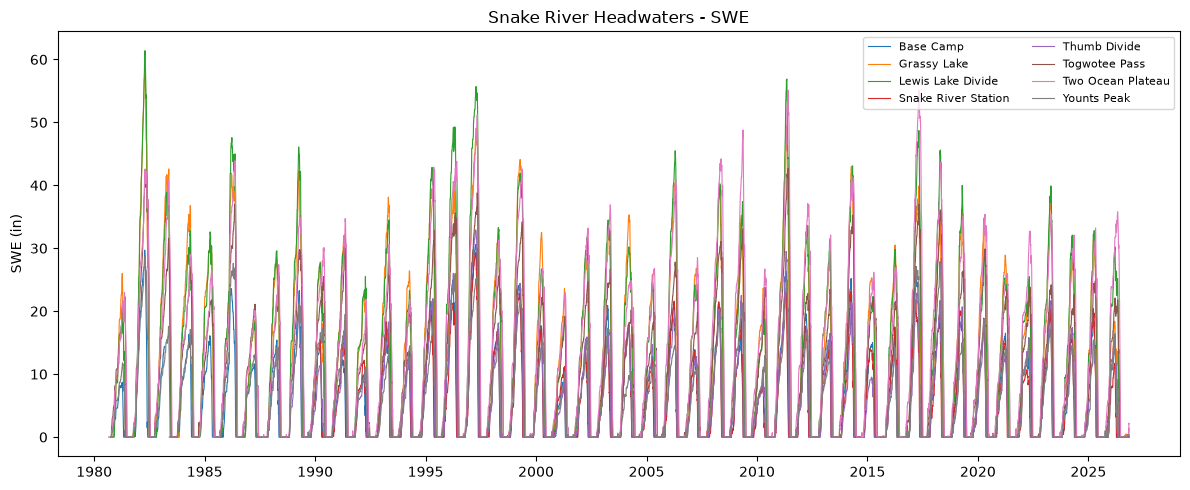

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
for name, g in df.groupby("site_name"):
    if "WTEQ" in g:
        ax.plot(g["date"], g["WTEQ"], label=name, lw=0.8)
ax.set_title("Snake River Headwaters - SWE"); ax.set_ylabel("SWE (in)"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()